<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory Ch 1 — Figure Notebook
**Classical String: Worldsheet, Mode Expansion, Light-cone Gauge**

Run Setup first, then each figure cell independently.

In [1]:
# ── Setup ────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
SKYB = '#89c4f4'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG,  'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': SKYB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

os.makedirs('figures/ch01', exist_ok=True)

def save(name, fig):
    fig.savefig(f'figures/ch01/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show(); print(f'Saved: figures/ch01/{name}')

print('Setup complete.')


Setup complete.


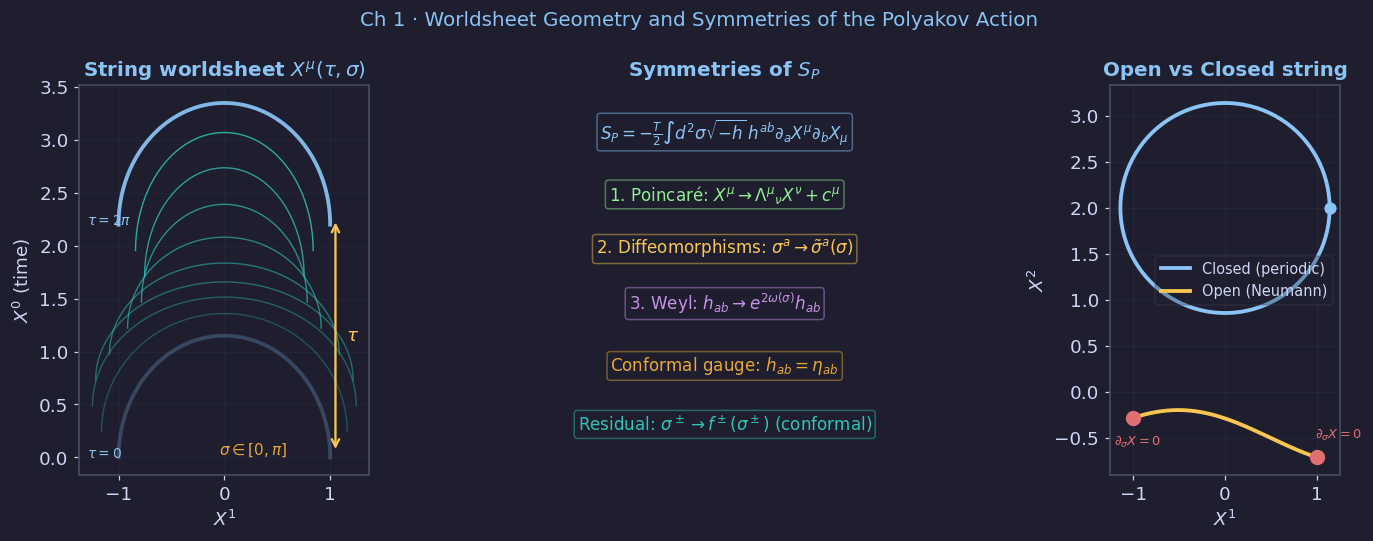

Saved: figures/ch01/fig01_worldsheet_symmetries.png


In [2]:
# ── fig01: Worldsheet geometry and symmetries ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Ch 1 · Worldsheet Geometry and Symmetries of the Polyakov Action',
             color=SKYB, fontsize=13)

# Left: string sweeps worldsheet in spacetime
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'String worldsheet $X^\mu(\tau,\sigma)$', color=SKYB)
sigma = np.linspace(0, np.pi, 80)
tau_vals = np.linspace(0, 2*np.pi, 10)
for i, tau in enumerate(tau_vals):
    x = np.cos(sigma) * (1 + 0.25*np.sin(tau))
    y = np.sin(sigma) * (1 + 0.15*np.cos(tau))
    alpha = 0.25 + 0.75*i/len(tau_vals)
    col = SKYB if i in [0, len(tau_vals)-1] else TEAL
    lw = 2.5 if i in [0, len(tau_vals)-1] else 0.9
    ax.plot(x, y + 0.35*tau, color=col, lw=lw, alpha=alpha)

# worldsheet coordinate arrows
ax.annotate('', xy=(1.05, 0.05), xytext=(1.05, 0.35*2*np.pi+0.05),
            arrowprops=dict(arrowstyle='<->', color=YELL, lw=1.5))
ax.text(1.15, 0.35*np.pi, r'$\tau$', color=YELL, fontsize=12)
ax.text(-0.05, 0.03, r'$\sigma\in[0,\pi]$', color=ORAN, fontsize=10)
ax.text(-1.3, 0.0,   r'$\tau=0$',    color=SKYB, fontsize=9)
ax.text(-1.3, 0.35*2*np.pi, r'$\tau=2\pi$', color=SKYB, fontsize=9)
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^0$ (time)')
ax.grid(True, alpha=0.15); ax.set_aspect('equal')

# Middle: Polyakov action symmetries
ax = axes[1]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Symmetries of $S_P$', color=SKYB)
items = [
    (0.5, 0.88, r'$S_P = -\frac{T}{2}\int d^2\sigma\sqrt{-h}\,h^{ab}\partial_a X^\mu\partial_b X_\mu$', SKYB),
    (0.5, 0.72, r'1. Poincaré: $X^\mu\to\Lambda^\mu{}_\nu X^\nu+c^\mu$', GREEN),
    (0.5, 0.58, r'2. Diffeomorphisms: $\sigma^a\to\tilde\sigma^a(\sigma)$', YELL),
    (0.5, 0.44, r'3. Weyl: $h_{ab}\to e^{2\omega(\sigma)}h_{ab}$', PURP),
    (0.5, 0.28, r'Conformal gauge: $h_{ab}=\eta_{ab}$', ORAN),
    (0.5, 0.13, r'Residual: $\sigma^\pm\to f^\pm(\sigma^\pm)$ (conformal)', TEAL),
]
for x_, y_, txt, col in items:
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=11, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.45))

# Right: open vs closed string boundary conditions
ax = axes[2]; ax.set_facecolor(BG)
ax.set_title('Open vs Closed string', color=SKYB)
sigma_o = np.linspace(0, np.pi, 200)
sigma_c = np.linspace(0, 2*np.pi, 200)
tau_plot = 0.8

# Closed: periodic
x_cl = np.cos(sigma_c) * (1 + 0.2*np.cos(tau_plot))
y_cl = np.sin(sigma_c) * (1 + 0.2*np.sin(tau_plot)) + 2.0
ax.plot(x_cl, y_cl, color=SKYB, lw=2.5, label='Closed (periodic)')
ax.plot(x_cl[0], y_cl[0], 'o', color=SKYB, ms=7)

# Open: endpoints free
amp = 0.3
x_op = sigma_o/np.pi * 2 - 1
y_op = amp * np.sin(sigma_o + tau_plot) - 0.5
ax.plot(x_op, y_op, color=YELL, lw=2.5, label='Open (Neumann)')
ax.plot([x_op[0],x_op[-1]], [y_op[0],y_op[-1]], 'o', color=RED, ms=9, zorder=6)
ax.text(x_op[0]+0.3, y_op[0]-0.3, r'$\partial_\sigma X=0$', fontsize=8.5,
        color=RED, ha='right')
ax.text(x_op[-1]-0.02, y_op[-1]+0.2, r'$\partial_\sigma X=0$', fontsize=8.5,
        color=RED, ha='left')

ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2); ax.set_aspect('equal')
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$')

plt.tight_layout()
save('fig01_worldsheet_symmetries.png', fig)


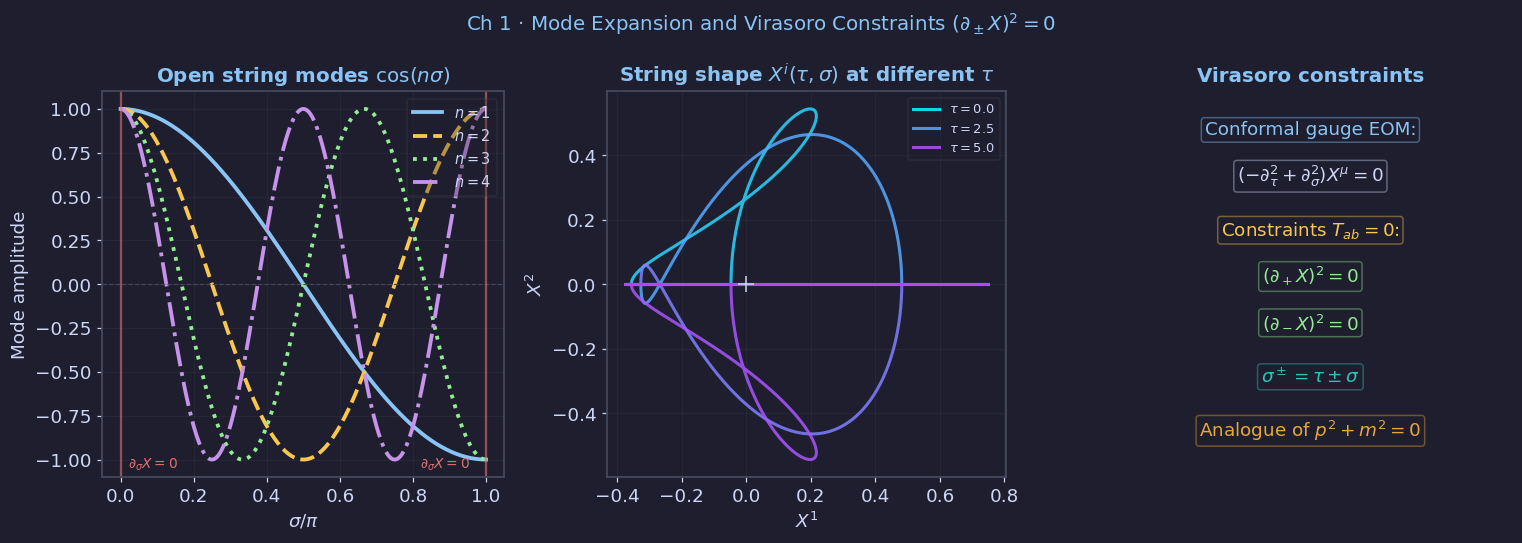

Saved: figures/ch01/fig02_mode_expansion.png


In [3]:
# ── fig02: Mode expansion and Virasoro constraints ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle(r'Ch 1 · Mode Expansion and Virasoro Constraints $(\partial_\pm X)^2=0$',
             color=SKYB, fontsize=13)

sigma_vals = np.linspace(0, np.pi, 300)
tau_vals_plot = np.linspace(0, 2*np.pi, 6)

# Left: individual modes
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Open string modes $\cos(n\sigma)$', color=SKYB)
for n, col, ls in [(1,SKYB,'-'),(2,YELL,'--'),(3,GREEN,':'),(4,PURP,'-.')]:
    ax.plot(sigma_vals/np.pi, np.cos(n*sigma_vals),
            color=col, lw=2.5, ls=ls, label=f'$n={n}$')
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.axvline(0, color=RED, lw=1.5, alpha=0.6)
ax.axvline(1, color=RED, lw=1.5, alpha=0.6)
ax.text(0.02, -1.05, r'$\partial_\sigma X=0$', color=RED, fontsize=9) #, transform=ax.transAxes)
ax.text(0.82, -1.05, r'$\partial_\sigma X=0$', color=RED, fontsize=9) #, transform=ax.transAxes)
ax.set_xlabel(r'$\sigma/\pi$'); ax.set_ylabel(r'Mode amplitude')
ax.legend(fontsize=9.5, loc='upper right'); ax.grid(True, alpha=0.2)

# Middle: snapshot of string shape at various tau
ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r'String shape $X^i(\tau,\sigma)$ at different $\tau$', color=SKYB)
cmap = plt.cm.cool
for i, tau in enumerate(tau_vals_plot):
    # superposition of modes 1 and 2
    x = (0.5*np.cos(sigma_vals)*np.cos(tau) +
         0.25*np.cos(2*sigma_vals)*np.cos(2*tau))
    y = (0.5*np.sin(sigma_vals)*np.sin(tau) +
         0.25*np.sin(2*sigma_vals)*np.sin(2*tau))
    col = cmap(i/len(tau_vals_plot))
    ax.plot(x, y, color=col, lw=2, alpha=0.85,
            label=fr'$\tau={tau:.1f}$' if i in [0,2,4] else '')
ax.plot(0, 0, '+', color=FG, ms=10, lw=2)
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$')
ax.legend(fontsize=8.5, loc='upper right'); ax.grid(True, alpha=0.2)
ax.set_aspect('equal')

# Right: Virasoro constraint visualisation
ax = axes[2]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Virasoro constraints', color=SKYB)
items = [
    (0.5, 0.90, r'Conformal gauge EOM:', SKYB),
    (0.5, 0.78, r'$(-\partial_\tau^2+\partial_\sigma^2)X^\mu=0$', FG),
    (0.5, 0.64, r'Constraints $T_{ab}=0$:', YELL),
    (0.5, 0.52, r'$(\partial_+ X)^2 = 0$', GREEN),
    (0.5, 0.40, r'$(\partial_- X)^2 = 0$', GREEN),
    (0.5, 0.26, r'$\sigma^\pm=\tau\pm\sigma$', TEAL),
    (0.5, 0.12, r'Analogue of $p^2+m^2=0$', ORAN),
]
for x_, y_, txt, col in items:
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=12, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.4))

plt.tight_layout()
save('fig02_mode_expansion.png', fig)


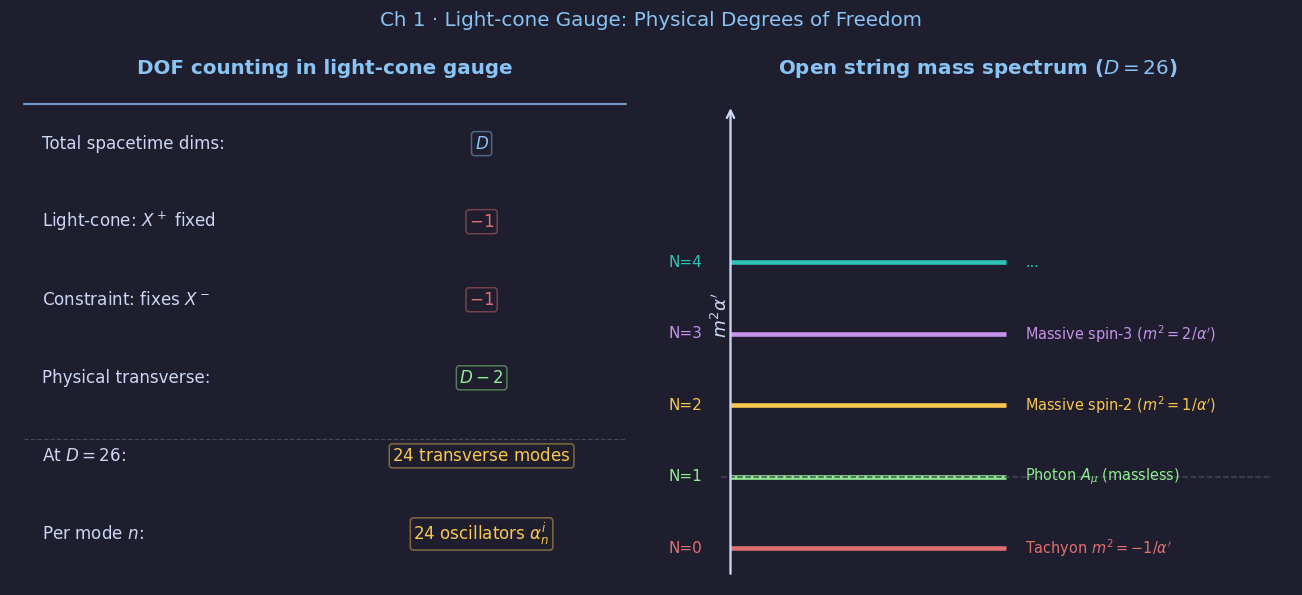

Saved: figures/ch01/fig03_lightcone_spectrum.png


In [4]:
# ── fig03: Light-cone gauge and physical degrees of freedom ──────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 1 · Light-cone Gauge: Physical Degrees of Freedom',
             color=SKYB, fontsize=13)

# Left: degrees of freedom count
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('DOF counting in light-cone gauge', color=SKYB)

rows = [
    (r'Total spacetime dims:', r'$D$', SKYB),
    (r'Light-cone: $X^+$ fixed', r'$-1$', RED),
    (r'Constraint: fixes $X^-$', r'$-1$', RED),
    (r'Physical transverse:', r'$D-2$', GREEN),
    (r'At $D=26$:', r'$24$ transverse modes', YELL),
    (r'Per mode $n$:', r'$24$ oscillators $\alpha^i_n$', YELL),
]
ys = np.linspace(0.88, 0.10, len(rows))
for (lbl, val, col), y in zip(rows, ys):
    ax.text(0.05, y, lbl, ha='left', va='center', fontsize=11,
            color=FG, transform=ax.transAxes)
    ax.text(0.75, y, val, ha='center', va='center', fontsize=11,
            color=col, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.45))

ax.plot([0.02, 0.98], [0.96, 0.96], color=SKYB, lw=1, transform=ax.transAxes)
ax.plot([0.02, 0.98], [0.29, 0.29], color=EDGE, lw=0.8, ls='--', transform=ax.transAxes)

# Right: mass spectrum tower
ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r'Open string mass spectrum ($D=26$)', color=SKYB)
ax.set_xlim(-0.3, 3); ax.set_ylim(-1.5, 5.5); ax.axis('off')

levels = [
    (-1, 'N=0', r'Tachyon $m^2=-1/\alpha^{\prime}$', RED),
    ( 0, 'N=1', r'Photon $A_\mu$ (massless)', GREEN),
    ( 1, 'N=2', r'Massive spin-2 ($m^2=1/\alpha^{\prime}$)', YELL),
    ( 2, 'N=3', r'Massive spin-3 ($m^2=2/\alpha^{\prime}$)', PURP),
    ( 3, 'N=4', r'...', TEAL),
]
for m2, lbl, desc, col in levels:
    ax.hlines(m2, 0.05, 1.5, colors=col, lw=3)
    ax.text(-0.1, m2, lbl, ha='right', va='center', fontsize=10, color=col)
    ax.text(1.6, m2, desc, ha='left', va='center', fontsize=9.5, color=col)

# y-axis
ax.annotate('', xy=(0.05, 5.2), xytext=(0.05, -1.4),
            arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
ax.text(0.0, 2, r"$m^2\alpha'$", ha='center', fontsize=12, color=FG, rotation=90)
# dashed zero line
ax.hlines(0, 0, 2.9, colors=EDGE, lw=1, ls='--')

plt.tight_layout()
save('fig03_lightcone_spectrum.png', fig)


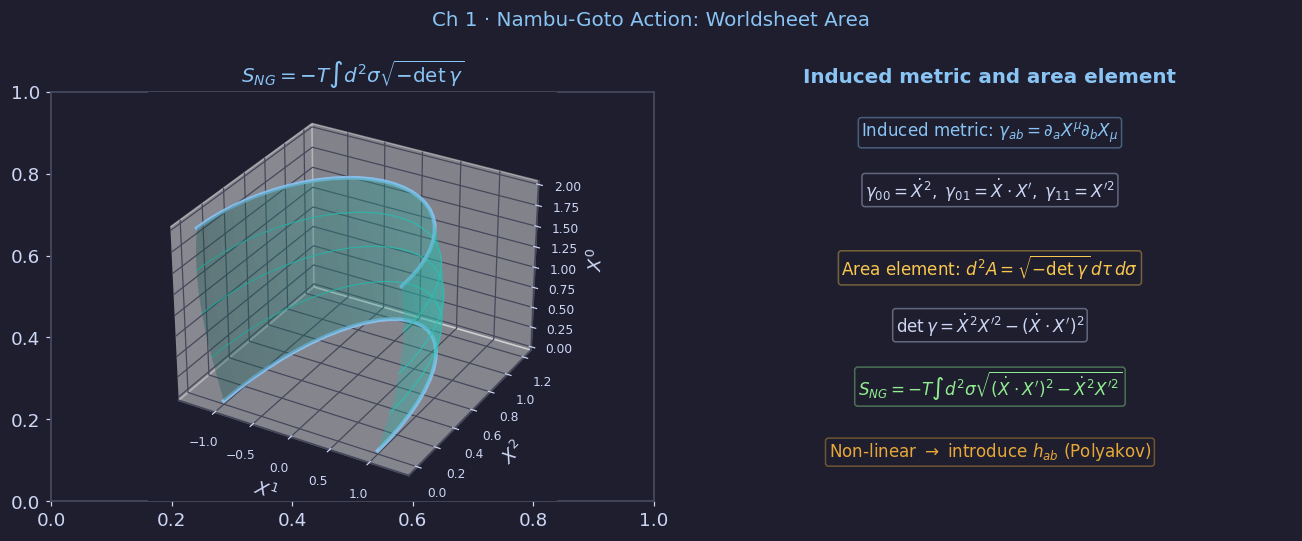

Saved: figures/ch01/fig04_nambu_goto_area.png


In [5]:
# ── fig04: Nambu-Goto action — area visualisation ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r'Ch 1 · Nambu-Goto Action: Worldsheet Area',
             color=SKYB, fontsize=13)

from mpl_toolkits.mplot3d import Axes3D  # noqa

# Left: 3D worldsheet surface
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.set_facecolor(BG)
ax.set_title(r'$S_{NG}=-T\int d^2\sigma\sqrt{-\det\gamma}$', color=SKYB)

tau_g = np.linspace(0, 2, 30)
sig_g = np.linspace(0, np.pi, 30)
TAU, SIG = np.meshgrid(tau_g, sig_g)
X = np.cos(SIG) * (1 + 0.3*np.sin(TAU))
Y = np.sin(SIG) * (1 + 0.2*np.cos(TAU))
Z = TAU

ax.plot_surface(X, Y, Z, alpha=0.35, color=TEAL, linewidth=0)
# Draw boundary strings
for t in [0, 0.5, 1.0, 1.5, 2.0]:
    x_ = np.cos(sig_g)*(1+0.3*np.sin(t))
    y_ = np.sin(sig_g)*(1+0.2*np.cos(t))
    z_ = np.full_like(sig_g, t)
    col = SKYB if t in [0, 2.0] else TEAL
    lw = 2.5 if t in [0, 2.0] else 0.8
    ax.plot(x_, y_, z_, color=col, lw=lw, alpha=0.9)

ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$'); ax.set_zlabel(r'$X^0$')
ax.tick_params(labelsize=8)

# Right: induced metric explanation
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('Induced metric and area element', color=SKYB)
items = [
    (0.5, 0.90, r'Induced metric: $\gamma_{ab}=\partial_a X^\mu\partial_b X_\mu$', SKYB),
    (0.5, 0.76, r'$\gamma_{00}=\dot X^2,\;\gamma_{01}=\dot X\cdot X^{\prime},\;\gamma_{11}=X^{\prime 2}$', FG),
    (0.5, 0.57, r'Area element: $d^2A = \sqrt{-\det\gamma}\,d\tau\,d\sigma$', YELL),
    (0.5, 0.43, r'$\det\gamma = \dot X^2 X^{\prime 2}-(\dot X\cdot X^{\prime})^2$', FG),
    (0.5, 0.28, r'$S_{NG} = -T\int d^2\sigma\sqrt{(\dot X\cdot X^{\prime})^2-\dot X^2 X^{\prime 2}}$', GREEN),
    (0.5, 0.12, r'Non-linear $\rightarrow$ introduce $h_{ab}$ (Polyakov)', ORAN),
]
for x_, y_, txt, col in items:
    ax2.text(x_, y_, txt, ha='center', va='center', fontsize=11, color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.4))

plt.tight_layout()
save('fig04_nambu_goto_area.png', fig)


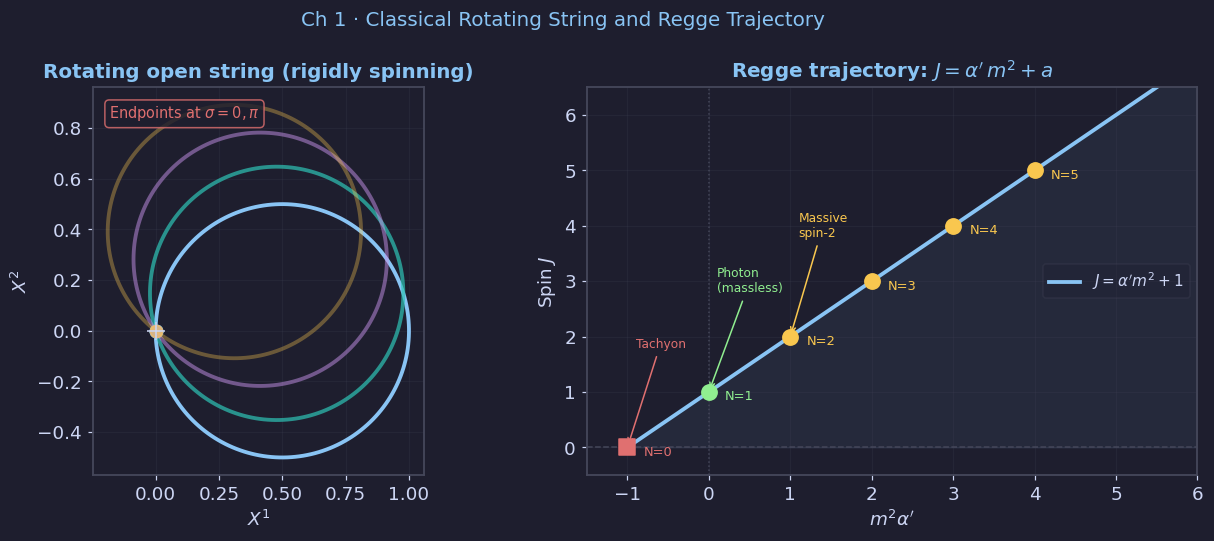

Saved: figures/ch01/fig05_rotating_string_regge.png


In [6]:
# ── fig05: Classical rotating string (Regge trajectory) ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Ch 1 · Classical Rotating String and Regge Trajectory',
             color=SKYB, fontsize=13)

# Left: rotating open string
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title('Rotating open string (rigidly spinning)', color=SKYB)
sigma_r = np.linspace(0, np.pi, 200)
omega = 1.0  # angular velocity

for tau_r, col, alpha in [(0, SKYB, 1.0), (0.3, TEAL, 0.7),
                           (0.6, PURP, 0.5), (0.9, YELL, 0.35)]:
    x = np.cos(omega*tau_r + sigma_r - np.pi/2) * np.sin(sigma_r)
    y = np.sin(omega*tau_r + sigma_r - np.pi/2) * np.sin(sigma_r)
    ax.plot(x, y, color=col, lw=2.5, alpha=alpha)
    ax.plot([x[0], x[-1]], [y[0], y[-1]], 'o', color=col, ms=8, alpha=alpha)

ax.plot(0, 0, '+', color=FG, ms=12, lw=2, zorder=8)
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$')
ax.set_aspect('equal'); ax.grid(True, alpha=0.2)
ax.text(0.05, 0.92, r'Endpoints at $\sigma=0,\pi$',
        transform=ax.transAxes, fontsize=9.5, color=RED,
        bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))

# Right: Regge trajectory J vs m^2
ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r"Regge trajectory: $J = \alpha'\, m^2 + a$", color=SKYB)
m2_cont = np.linspace(-1, 6, 300)
J_cont  = m2_cont + 1   # open string, a=1

ax.plot(m2_cont, J_cont, color=SKYB, lw=2.5, label=r"$J=\alpha'm^2+1$")
ax.fill_between(m2_cont, 0, J_cont,
                where=(J_cont>=0)&(m2_cont>=-1), color=SKYB, alpha=0.07)

# discrete levels
for N in range(6):
    m2v = N - 1
    Jv  = N
    mk = 's' if N == 0 else 'o'
    col = RED if N==0 else GREEN if N==1 else YELL
    ax.scatter([m2v], [Jv], color=col, s=100, zorder=7, marker=mk)
    ax.text(m2v+0.2, Jv-0.15, f'N={N}', fontsize=8.5, color=col)

ax.axhline(0, color=EDGE, lw=1, ls='--')
ax.axvline(0, color=EDGE, lw=1, ls=':')
ax.set_xlabel(r"$m^2\alpha'$"); ax.set_ylabel(r'Spin $J$')
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
ax.set_xlim(-1.5, 6); ax.set_ylim(-0.5, 6.5)

# labels
for (m2v, Jv, lbl, col) in [
    (-1, 0, 'Tachyon', RED),
    ( 0, 1, 'Photon\n(massless)', GREEN),
    ( 1, 2, 'Massive\nspin-2', YELL),
]:
    ax.annotate(lbl, xy=(m2v, Jv),
                xytext=(m2v+0.1, Jv+1.8),
                fontsize=8, color=col,
                arrowprops=dict(arrowstyle='->', color=col, lw=1))

plt.tight_layout()
save('fig05_rotating_string_regge.png', fig)


In [7]:
# ── Download all figures as a zip ────────────────────────────────────────
import shutil

shutil.make_archive('ch01_figures', 'zip', 'figures/ch01')

try:
    from google.colab import files
    files.download('ch01_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch01/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
